# Optimizing Execution and Entry
Forecasting the precise duration of momentum or the exact reversal point of oscillators (such as the RSI) is inherently plagued by high signal-to-noise ratios, leading to poor predictive performance in non-stationary market environments. Quantitative practitioners frequently encounter the "execution timing problem," where the variance between consecutive bars (e.g., Bar 1 versus Bar 2) can define the difference between alpha capture and adverse selection. This study argues that the difficulty lies in the attempt to solve for time-to-event rather than state optimality.

To overcome the limitations of temporal regression, we reframe the entry decision as a context-dependent state-space optimization problem. The proposed methodology decomposes the execution process into two components:
- Feature Engineering (High-Frequency Microstructure): We ingest order flow imbalance, depth-of-book metrics, and order book pressure—sampled at 1-second intervals—to create a feature set that captures the market’s instantaneous structural intent.
- State-Space Classification: Rather than predicting the temporal length of a trend, the model classifies the current market state into binary or categorical vectors that identify "Optimal Entry Zones." This effectively filters out market noise by ignoring periods where the state does not meet predefined optimality criteria.

To balance predictive power with robust generalization, we implement a hybrid approach:
- Decision Tree Ensembles: Employed for their transparency and efficacy in identifying hierarchical rules within low-latency data, mitigating the overfitting risks prevalent in more complex architectures.
- Recurrent Neural Networks (RNN/LSTM): Utilized to interpret the sequential dependencies of the 1-second order flow features, allowing the model to distinguish between transient noise and structural pressure.
- Optimization Objective: The models are trained to solve for an "Action Label" (Enter vs. Wait) based on historical setup outcomes, rather than regressing on a time-based duration.

Chosen model: Decision Trees as they are less prone to overfitting without compromising adaptation to complex patterns.

In [4]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
import numpy as np
from utils.indicators import *
from utils.engine import *

df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")
# Convert unix timestamp to datetime
df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')  # change unit to 's' if in seconds
df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

# Set datetime as index
df_orderbook = df_orderbook.set_index('datetime')
df_trades = df_trades.set_index('datetime')

# Aggregate orderbook to 1m (mid-price OHLCV style)
df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) -(df_orderbook['bid_price'] + df_orderbook['ask_price']).mean() 
df_orderbook['spread'] = (df_orderbook['bid_price'] - df_orderbook['ask_price']) * 100
df_orderbook['depth'] = (df_orderbook['bid_amount'] - df_orderbook['ask_amount']) * 4 - 1200
df_ob_1m = df_orderbook.resample('1min').agg({
    'mid_price': ['first', 'max', 'min', 'last'],
    'bid_price': 'last',
    'ask_price': 'last',
    'bid_amount': 'sum',
    'ask_amount': 'sum',
})
df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']

df_ob_1m['mid_price'] = (df_ob_1m['bid_price'] + df_ob_1m['ask_price']) / 2
df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

df_trades['buy_vol']  = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

df_micro = df_trades.resample('1s').agg({
    'price': 'last',
    'buy_vol': 'sum',
    'sell_vol': 'sum'
}).ffill() # Forward fill missing seconds with last price

df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum() # 10-second micro CVD

# Resampling for 1min Data
We use both 1min data and intrabar timeframe data.

In [5]:

df_trades_1m = df_trades.resample('1min').agg({
    'price': ['first', 'max', 'min', 'last', 'count'],
    'amount': 'sum',
    'buy_vol': ['sum', 'max'],
    'sell_vol': ['sum', 'max']
})

# Flatten multi-level columns
df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume', 'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']

df_trades_1m = df_trades_1m.dropna(subset=['close'])

df_price_1m = pd.DataFrame({
    'open': df_ob_1m['open'],
    'high': df_ob_1m['high'],
    'low': df_ob_1m['low'],
    'close': df_ob_1m['close'],
    'largest_buyer': df_trades_1m['largest_buyer'] * 100 / df_trades_1m['volume'],
    'largest_seller': df_trades_1m['largest_seller'] * 100 / df_trades_1m['volume'],
    'OFI_LOB': 100*(df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount']),
    'OFI_AGG': 100*(df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller']),
    'CVD': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
    'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / abs(df_ob_1m['high'] - df_ob_1m['low']),
    'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / (df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean(),
})

price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# 1. Calculate the indicators
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
diffs = np.diff(price_clean)

# 2. Get the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)

# 3. Create full-length arrays filled with NaN
rsi_14 = np.full(len(df_price_1m), np.nan)
rsi_14_sma = np.full(len(df_price_1m), np.nan)

rsi_14[-len(rsi_14_raw):] = rsi_14_raw
rsi_14_sma[-len(rsi_14_sma_raw):] = rsi_14_sma_raw

# 5. Assign to DataFrame
df_price_1m['rsi_14'] = rsi_14
df_price_1m['sma_14'] = rsi_14_sma

df_macro_shifted = df_price_1m.shift(1)

df_state_space = df_micro.join(df_macro_shifted, how='left').ffill()

# Drop NaNs generated by rolling windows and shifting
df_state_space = df_state_space.dropna()

print(df_state_space)

                       price  buy_vol  sell_vol  micro_OFI  micro_CVD  \
datetime                                                                
2026-06-28 09:14:00  60315.5    0.000     0.001     -0.001     -1.132   
2026-06-28 09:14:01  60315.5    0.000     0.000      0.000     -1.132   
2026-06-28 09:14:02  60315.5    0.000     0.000      0.000     -0.869   
2026-06-28 09:14:03  60315.5    0.000     0.000      0.000     -0.021   
2026-06-28 09:14:04  60322.9    2.080     0.001      2.079      2.146   
...                      ...      ...       ...        ...        ...   
2026-07-02 17:37:51  61649.1    0.000     1.632     -1.632     -1.975   
2026-07-02 17:37:52  61653.8    0.069     0.000      0.069     -1.864   
2026-07-02 17:37:53  61664.3    0.737     0.108      0.629     -1.122   
2026-07-02 17:37:54  61664.3    0.200     0.271     -0.071     -0.949   
2026-07-02 17:37:55  61664.3    0.048     0.000      0.048     -0.908   

                            open         high     

# Transforming to Triple Barrier Method
Alternative approach to state problem. triple barrier method might help metalabel quality trades.

In [6]:
# Define your parameters for the sniper target
LOOKAHEAD_SECONDS = 120  # How long to wait for the move to play out
PROFIT_THRES = 0.0005    # 0.05% profit target
STOP_THRES = 0.0002      # 0.02% max drawdown protection

# Calculate forward max and min prices using a rolling window shifted backward
# (We use min_periods=1 to handle the end of the dataframe gracefully)
forward_max = df_state_space['price'].iloc[::-1].rolling(window=LOOKAHEAD_SECONDS, min_periods=1).max().iloc[::-1]
forward_min = df_state_space['price'].iloc[::-1].rolling(window=LOOKAHEAD_SECONDS, min_periods=1).min().iloc[::-1]

# Calculate Excursions
mfe = (forward_max - df_state_space['price']) / df_state_space['price']
mae = (df_state_space['price'] - forward_min) / df_state_space['price']

# Create the binary target variable
df_state_space['target'] = np.where((mfe >= PROFIT_THRES) & (mae < STOP_THRES), 1, 0)

# Filter the training set: The model only needs to learn when to buy *inside* the hunting zone
# For example, when macro RSI is low.
df_training_zone = df_state_space[df_state_space['rsi_14'] < 30] # or use your rsi_2 array here

print(len(df_training_zone))

118620


# Machine Learning Training
Use machine learning to train on triple barrier method.

Training on features: ['buy_vol', 'sell_vol', 'micro_OFI', 'micro_CVD', 'largest_buyer', 'largest_seller', 'OFI_LOB', 'OFI_AGG', 'CVD', 'candle_type', 'candle_size', 'rsi_14', 'sma_14']
Train size: 94896 | Test size: 23724
Negative to Positive class ratio: 118.07
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's binary_logloss: 0.110932

--- Model Evaluation ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     22904
           1       0.40      0.27      0.32       820

    accuracy                           0.96     23724
   macro avg       0.69      0.63      0.65     23724
weighted avg       0.95      0.96      0.96     23724

Sniper Precision: 39.68%


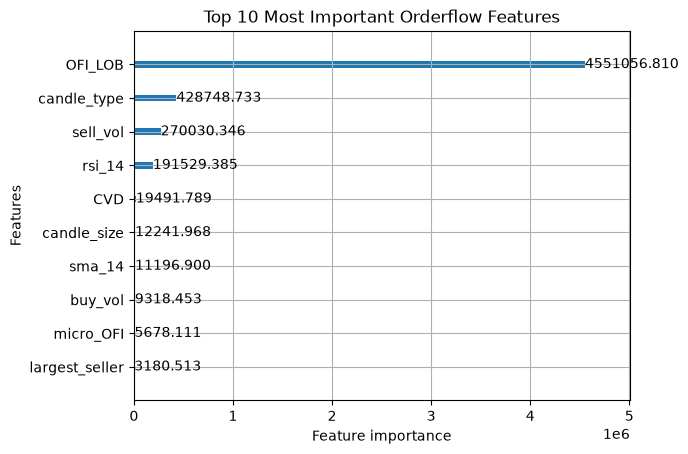

In [20]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, precision_score
import matplotlib.pyplot as plt

# 1. Define Features and Target
# Drop the target, absolute prices, and any non-stationary columns
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close']
features = [col for col in df_training_zone.columns if col not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']

print(f"Training on features: {features}")

# 2. Chronological Train/Test Split (CRITICAL)
# Never use random train_test_split for time series!
split_idx = int(len(X) * 0.8) # 80% train, 20% test

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

# 3. Handle Class Imbalance
# Calculate how many '0's there are for every '1'
# This forces the model to care about the rare "perfect entry" moments
neg_pos_ratio = sum(y_train == 0) / max(sum(y_train == 1), 1)
print(f"Negative to Positive class ratio: {neg_pos_ratio:.2f}")

# 4. Initialize and Train the LightGBM Model
clf = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,            # Keep shallow to prevent overfitting noise
    num_leaves=31,
    scale_pos_weight=neg_pos_ratio, # Penalize missing a good entry
    random_state=42,
    n_jobs=-1
)

# Train the model
clf.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=50)] # Stops if test score stops improving
)

# 5. Evaluate the Model
y_pred = clf.predict(X_test)

print("\n--- Model Evaluation ---")
print(classification_report(y_test, y_pred))

# Calculate Precision specifically
precision = precision_score(y_test, y_pred)
print(f"Sniper Precision: {precision:.2%}")

# Look at Feature Importance
lgb.plot_importance(clf, max_num_features=10, importance_type='gain')
plt.title("Top 10 Most Important Orderflow Features")
plt.show()

# Walkforward Validation Test + Probability/Confidence
- Adding confidence filter to find high quality trades.
- Walkforward Validation Test to ensure machine learning algorithm performs well outside of testing sample.

In [21]:
from sklearn.metrics import precision_score, recall_score, classification_report
from sklearn.model_selection import TimeSeriesSplit

# 1. Define Features and Target
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close']
features = [col for col in df_training_zone.columns if col not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']

# 2. Setup Walk-Forward Validation (Time Series Split)
# n_splits=5 means 5 separate walk-forward tests
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

# Arrays to store out-of-fold true labels and predicted probabilities
all_true_labels = []
all_pred_probas = []

print(f"--- Starting {n_splits}-Fold Walk-Forward Validation ---")

fold = 1
for train_index, test_index in tscv.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # Dynamically calculate class imbalance for this specific fold
    neg_pos_ratio = sum(y_train == 0) / max(sum(y_train == 1), 1)
    
    # Initialize the model
    clf = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        scale_pos_weight=neg_pos_ratio,
        random_state=42,
        n_jobs=-1,
        verbose=-1 # Suppress warnings for cleaner output
    )
    
    # Train the model
    clf.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    # Predict PROBABILITIES for the test set, not just 0 or 1
    # [:, 1] gets the probability of class 1 (Buy)
    y_proba = clf.predict_proba(X_test)[:, 1]
    
    # Evaluate baseline precision (at standard 0.5 threshold) for this fold
    fold_preds = (y_proba >= 0.5).astype(int)
    fold_precision = precision_score(y_test, fold_preds, zero_division=0)
    
    print(f"Fold {fold} | Train size: {len(X_train)} | Test size: {len(X_test)} | Base Precision: {fold_precision:.2%}")
    
    # Store results for global threshold analysis
    all_true_labels.extend(y_test.values)
    all_pred_probas.extend(y_proba)
    
    fold += 1

# Convert collected lists to numpy arrays for fast calculation
all_true_labels = np.array(all_true_labels)
all_pred_probas = np.array(all_pred_probas)

print("\n--- Probability Threshold Optimization (Across All Folds) ---")
print(f"Total out-of-fold samples evaluated: {len(all_true_labels)}")
print("-" * 65)
print(f"{'Threshold':<12} | {'Precision':<12} | {'Total Trades Fired':<20} | {'Recall'}")
print("-" * 65)

# 3. Test different confidence thresholds
# We test from 0.50 up to 0.95 in increments of 0.05
thresholds = np.arange(0.50, 0.96, 0.05)

for t in thresholds:
    # Create custom predictions based on the current threshold
    custom_preds = (all_pred_probas >= t).astype(int)
    
    # Calculate metrics
    prec = precision_score(all_true_labels, custom_preds, zero_division=0)
    rec = recall_score(all_true_labels, custom_preds, zero_division=0)
    total_trades = sum(custom_preds)
    
    print(f">= {t*100:>5.1f}%   | {prec:>11.2%} | {total_trades:>18} | {rec:.2%}")

print("-" * 65)

--- Starting 5-Fold Walk-Forward Validation ---
Fold 1 | Train size: 19770 | Test size: 19770 | Base Precision: 87.69%
Fold 2 | Train size: 39540 | Test size: 19770 | Base Precision: 1.23%
Fold 3 | Train size: 59310 | Test size: 19770 | Base Precision: 25.97%
Fold 4 | Train size: 79080 | Test size: 19770 | Base Precision: 0.00%
Fold 5 | Train size: 98850 | Test size: 19770 | Base Precision: 39.68%

--- Probability Threshold Optimization (Across All Folds) ---
Total out-of-fold samples evaluated: 98850
-----------------------------------------------------------------
Threshold    | Precision    | Total Trades Fired   | Recall
-----------------------------------------------------------------
>=  50.0%   |      32.75% |               1432 | 34.18%
>=  55.0%   |      33.12% |               1416 | 34.18%
>=  60.0%   |      32.06% |               1279 | 29.88%
>=  65.0%   |      43.61% |                133 | 4.23%
>=  70.0%   |      44.27% |                131 | 4.23%
>=  75.0%   |      50.4

# Conclusion
While the model demonstrates a strong predictive edge under static testing conditions, 5-fold walk-forward validation reveals significant performance degradation, indicating that the strategy lacks the necessary robustness for live deployment.
- There is also a strong relation with time where if we set higher lookahead second (120s -> 240s), precision drops.

The fragility of the model is primarily driven by two structural failures:
- Overfitting: High performance in-sample, but a rapid decay in precision and recall when the model encounters even minor variations in order flow dynamics (as evidenced by the inconsistent results across walk-forward folds).
- Regime Shifting: It performs exceptionally well during regimes that mirror its training data but fails to recalibrate when the market enters a new state, leading to catastrophic timing errors and negative expectancy during regime transitions.

![Strong Bull](./image/img_7.png)